# Cameron Peak and East Troublesome Fire Burn Severity
## Vegetation Recovery

- **Objective:**
For this notebook, vegetation recovery after the 2020 Cameron Peak and East Troublesome fires is tracked from 2021 to 2026 with the HLS summer NDVI composites from 01_data_download, for each Key and Benson burn severity class from 02_burn_severity.

- **Objective goals:**
    - Average the summer NDVI in each burn severity class for every year
    - Compare the burned areas with unburned land outside the fires
    - Measure how much of the NDVI lost in the fires has come back by each year
    - Map the recovery and save the table

---

### Methodology

#### 1. Load the NDVI Composites
- Open the NDVI composites and the burn severity classes
- Find the pixels inside the perimeters and the unburned land outside them

#### 2. NDVI by Burn Severity Class
- Average the NDVI in each burned class for every year, and for the unburned land

#### 3. Recovery
- Measure how much of the NDVI lost from 2019 to 2021 has come back, compared with the unburned land
- Map the recovery by 2026

#### 4. Save the Results
- Save the NDVI and recovery table

#### 5. Summary
- Sum up how the burned areas have recovered

# Libraries

In [1]:
### file paths, OS operations, utilities
import os
import pathlib

### data handling
import numpy as np
import pandas as pd
import geopandas as gpd

### rasters
import rioxarray as rxr
from rasterio.features import geometry_mask

### visualization
import matplotlib.pyplot as plt

# Primary Directory

In [2]:
### set up root file path
# Walk up from the current directory to find the repo root (contains .git)
_cwd = pathlib.Path(os.getcwd()).resolve()
repo_root = next(
    (p for p in [_cwd] + list(_cwd.parents) if (p / '.git').exists()),
    _cwd
)
os.chdir(repo_root)

data_dir = os.path.join(repo_root, 'data')
os.makedirs(data_dir, exist_ok=True)

print('Repo root:', repo_root)

Repo root: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity


# Secondary Directories

In [3]:
### set a directory for the vegetation recovery results
recovery_dir = os.path.join(data_dir, 'recovery')
os.makedirs(recovery_dir, exist_ok=True)

# Load the Saved Data
These are the Universal Calls cells from 01_data_download and 02_burn_severity, which load the data saved there.

In [4]:
### root dir
data_dir = os.path.join(repo_root, 'data')

### fire names used in the file names
fire_keys = ["cameron_peak", "east_troublesome"]


### PERIMETERS AND STUDY AREAS
perimeters_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'nifc_perimeters.gpkg'))
study_area_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'study_areas.gpkg'))


### MTBS
### fire records and dNBR thresholds
mtbs_fires_df = pd.read_csv(os.path.join(data_dir, 'mtbs', 'mtbs_fires.csv'))

### MTBS boundaries
mtbs_gdf = gpd.read_file(os.path.join(data_dir, 'mtbs', 'mtbs_boundaries.gpkg'))

### MTBS burn severity maps
mtbs_paths = {}
for fire in fire_keys:
    mtbs_paths[fire] = os.path.join(data_dir, 'mtbs', 'mtbs_' + fire + '_2020.tif')


### WATERSHEDS
huc12_gdf = gpd.read_file(os.path.join(data_dir, 'watersheds', 'huc12.gpkg'))


### WUI
wui_path = os.path.join(data_dir, 'wui', 'wui_CO_2019_clip.tif')


### HLS COMPOSITES
### e.g. hls_paths[("cameron_peak", 2021)]["nbr"]
hls_paths = {}
for fire in fire_keys:
    for year in range(2019, 2027):
        fire_hls_dir = os.path.join(data_dir, 'hls', fire)
        file_start = "hls_" + fire + "_" + str(year)
        hls_paths[(fire, year)] = {
            "nbr": os.path.join(fire_hls_dir, file_start + "_nbr.tif"),
            "ndvi": os.path.join(fire_hls_dir, file_start + "_ndvi.tif"),
            "count": os.path.join(fire_hls_dir, file_start + "_count.tif"),
            "scenes": os.path.join(fire_hls_dir, file_start + "_scenes.csv"),
        }

In [5]:
### BURN SEVERITY
severity_dir = os.path.join(data_dir, 'severity')

### Key and Benson class numbers, names, thresholds, and colors
severity_classes_df = pd.read_csv(os.path.join(severity_dir, 'severity_classes.csv'))

### acres and percent of each fire in each class
severity_area_df = pd.read_csv(os.path.join(severity_dir, 'severity_area.csv'))

### dNBR and burn severity classes for each fire, e.g. dnbr_paths["cameron_peak"]
dnbr_paths = {}
severity_class_paths = {}
for fire in fire_keys:
    dnbr_paths[fire] = os.path.join(severity_dir, fire, fire + '_dnbr.tif')
    severity_class_paths[fire] = os.path.join(severity_dir, fire, fire + '_severity_classes.tif')

### Settings

In [6]:
### summer before the fires, and the summers after
pre_fire_year = 2019
post_fire_year = 2021
recovery_years = list(range(post_fire_year, 2027))
years = [pre_fire_year] + recovery_years

### projected coordinate system of the rasters: UTM zone 13N (meters)
utm_crs = "EPSG:32613"

### unburned land is at least this far outside the perimeters (meters)
reference_buffer_m = 1000

### smallest drop in relative NDVI from 2019 to 2021 shown on the recovery map
min_ndvi_drop = 0.1

# 1. Load the NDVI Composites
NDVI is opened for 2019 and 2021-2026. Two groups of pixels are used: the pixels inside each perimeter, which are split up by burn severity class, and unburned land more than 1km outside both perimeters. The unburned land shows how much NDVI changes from year to year from weather alone, so a wet or dry summer isn't mistaken for recovery.

In [7]:
### project the perimeters to UTM zone 13N to match the rasters
perimeters_utm = perimeters_gdf.to_crs(utm_crs)

### land within 1km of either fire, left out of the unburned land
near_fires = perimeters_utm.buffer(reference_buffer_m)

### open the burn severity classes and NDVI composites, and make the masks for each fire
class_values = {}
ndvi_values = {}
inside_masks = {}
reference_masks = {}
extents = {}

for fire in fire_keys:

    ### burn severity classes (0 is no data)
    classes_da = rxr.open_rasterio(severity_class_paths[fire]).squeeze()
    class_values[fire] = classes_da.values
    transform = classes_da.rio.transform()
    left, bottom, right, top = classes_da.rio.bounds()
    extents[fire] = [left, right, bottom, top]

    ### NDVI for each year (NaN is no data), and the pixels with a clear look in every year
    clear_every_year = np.ones(class_values[fire].shape, dtype=bool)
    for year in years:
        ndvi_values[(fire, year)] = rxr.open_rasterio(hls_paths[(fire, year)]["ndvi"], masked=True).squeeze().values
        clear_every_year = clear_every_year & ~np.isnan(ndvi_values[(fire, year)])

    ### pixels inside the perimeter, and unburned land more than 1km outside both perimeters
    perimeter = perimeters_utm[perimeters_utm["fire"] == fire]
    inside = geometry_mask(perimeter.geometry, out_shape=class_values[fire].shape, transform=transform, invert=True)
    near = geometry_mask(near_fires, out_shape=class_values[fire].shape, transform=transform, invert=True)

    inside_masks[fire] = inside & clear_every_year
    reference_masks[fire] = ~near & clear_every_year

    ### check how much of the fire has a clear look every year
    clear_percent = inside_masks[fire].sum() / inside.sum() * 100
    print(fire + ": " + str(round(clear_percent, 1)) + "% of the area inside the perimeter has a clear look every year")

cameron_peak: 99.7% of the area inside the perimeter has a clear look every year


east_troublesome: 99.8% of the area inside the perimeter has a clear look every year


# 2. NDVI by Burn Severity Class
The mean NDVI is found for each burned Key and Benson class (Low through High) and for the unburned land, in every year (skipping 2020).

In [8]:
### the burned classes, and a name for the unburned land
burned_classes = ["Low", "Moderate-low", "Moderate-high", "High"]
reference_name = "Unburned, outside the fires"
class_numbers = dict(zip(severity_classes_df["class"], severity_classes_df["number"]))

### mean NDVI for each group of pixels in every year
rows = []

for fire in fire_keys:

    ### pixels in each burned class, and the unburned land
    groups = {}
    for name in burned_classes:
        groups[name] = inside_masks[fire] & (class_values[fire] == class_numbers[name])
    groups[reference_name] = reference_masks[fire]

    for group, mask in groups.items():
        for year in years:
            mean_ndvi = ndvi_values[(fire, year)][mask].mean()
            rows.append({"fire": fire, "group": group, "year": year, "mean_ndvi": mean_ndvi})

ndvi_df = pd.DataFrame(rows)

### check it
ndvi_df.pivot_table(index=["fire", "group"], columns="year", values="mean_ndvi", sort=False).round(3)

year                                           2019   2021   2022   2023  \
fire             group                                                     
cameron_peak     Low                          0.560  0.441  0.456  0.492   
                 Moderate-low                 0.581  0.337  0.382  0.424   
                 Moderate-high                0.611  0.256  0.318  0.372   
                 High                         0.682  0.225  0.292  0.351   
                 Unburned, outside the fires  0.501  0.506  0.482  0.530   
east_troublesome Low                          0.548  0.428  0.485  0.511   
                 Moderate-low                 0.561  0.337  0.423  0.472   
                 Moderate-high                0.593  0.270  0.364  0.425   
                 High                         0.681  0.232  0.328  0.391   
                 Unburned, outside the fires  0.536  0.503  0.529  0.537   

year                                           2024   2025   2026  
fire             group                                             
cameron_peak     Low                          0.446  0.460  0.430  
                 Moderate-low                 0.401  0.409  0.391  
                 Moderate-high                0.372  0.383  0.375  
                 High                         0.388  0.394  0.393  
                 Unburned, outside the fires  0.483  0.484  0.463  
east_troublesome Low                          0.474  0.475  0.421  
                 Moderate-low                 0.426  0.432  0.387  
                 Moderate-high                0.398  0.403  0.383  
                 High                         0.406  0.399  0.382  
                 Unburned, outside the fires  0.533  0.518  0.491

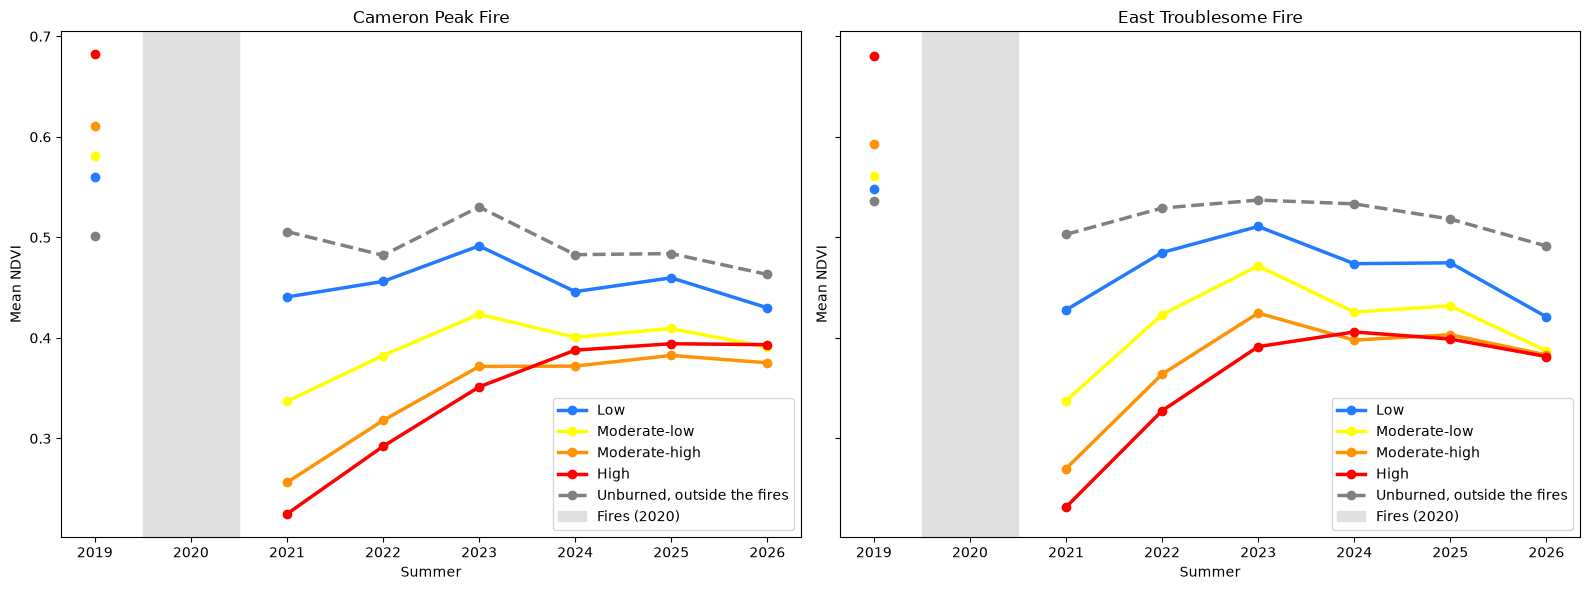

In [9]:
### line colors: the 02_burn_severity class colors, and gray for the unburned land
class_colors = dict(zip(severity_classes_df["class"], severity_classes_df["color"]))
line_colors = {name: class_colors[name] for name in burned_classes}
line_colors[reference_name] = "#808080"

### plot the mean NDVI of each group by year
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

for ax, fire in zip(axes, fire_keys):
    fire_df = ndvi_df[ndvi_df["fire"] == fire]

    for group, color in line_colors.items():
        group_df = fire_df[fire_df["group"] == group]
        before_df = group_df[group_df["year"] == pre_fire_year]
        after_df = group_df[group_df["year"] >= post_fire_year]

        ### 2019 as a dot, and a line from 2021 on (there's no 2020 data)
        ax.plot(before_df["year"], before_df["mean_ndvi"], color=color, marker="o")
        ax.plot(
            after_df["year"], after_df["mean_ndvi"], color=color, label=group,
            linestyle="--" if group == reference_name else "-", linewidth=2.5,
            marker="o"
        )

    ### shade the summer of the fires
    ax.axvspan(2019.5, 2020.5, color="#e0e0e0", label="Fires (2020)")

    ax.set_xticks(range(pre_fire_year, recovery_years[-1] + 1))
    ax.set_title(fire.replace("_", " ").title() + " Fire")
    ax.set_xlabel("Summer")
    ax.set_ylabel("Mean NDVI")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

Figure 1: Mean summer NDVI in each burned Key and Benson class, and on unburned land more than 1km outside the fires (dashed gray). 2020 is left out due to the fires.

# 3. Recovery
Recovery is the percent of the NDVI lost in the fires that has come back. The unburned land in Figure 1 goes up and down from year to year with the weather, so each year's NDVI is first compared with the unburned land in the same summer:

relative NDVI = NDVI - unburned NDVI

recovery = (relative NDVI in the year - relative NDVI 2021) / (relative NDVI 2019 - relative NDVI 2021) x 100

0% means no recovery since 2021, and 100% means the burned area is back to where it was compared with the unburned land in 2019.

In [10]:
### start from the NDVI table from section 2, so this cell can be rerun
ndvi_df = ndvi_df[["fire", "group", "year", "mean_ndvi"]]

### NDVI of the unburned land in each year, for each fire
reference_df = ndvi_df[ndvi_df["group"] == reference_name]
reference_df = reference_df[["fire", "year", "mean_ndvi"]].rename(columns={"mean_ndvi": "reference_ndvi"})
ndvi_df = ndvi_df.merge(reference_df, on=["fire", "year"])

### NDVI compared with the unburned land in the same summer, to take out changes from weather
ndvi_df["relative_ndvi"] = ndvi_df["mean_ndvi"] - ndvi_df["reference_ndvi"]

### relative NDVI before (2019) and right after (2021) the fires, for each fire and group
before_df = ndvi_df[ndvi_df["year"] == pre_fire_year][["fire", "group", "relative_ndvi"]].rename(columns={"relative_ndvi": "relative_before"})
after_df = ndvi_df[ndvi_df["year"] == post_fire_year][["fire", "group", "relative_ndvi"]].rename(columns={"relative_ndvi": "relative_after"})
ndvi_df = ndvi_df.merge(before_df, on=["fire", "group"])
ndvi_df = ndvi_df.merge(after_df, on=["fire", "group"])

### percent of the lost NDVI that has come back
lost = ndvi_df["relative_before"] - ndvi_df["relative_after"]
regained = ndvi_df["relative_ndvi"] - ndvi_df["relative_after"]
ndvi_df["recovery_percent"] = regained / lost * 100

### the unburned land is the comparison, so it has no recovery
ndvi_df.loc[ndvi_df["group"] == reference_name, "recovery_percent"] = np.nan

### recovery of each burned class by year
burned_df = ndvi_df[ndvi_df["group"] != reference_name]
burned_df.pivot_table(index=["fire", "group"], columns="year", values="recovery_percent", sort=False)[recovery_years].round(0)

year                            2021  2022  2023  2024  2025  2026
fire             group                                            
cameron_peak     Low             0.0  32.0  21.0  23.0  33.0  26.0
                 Moderate-low    0.0  28.0  25.0  35.0  38.0  39.0
                 Moderate-high   0.0  24.0  25.0  39.0  41.0  45.0
                 High            0.0  20.0  22.0  40.0  41.0  46.0
east_troublesome Low             0.0  35.0  56.0  18.0  36.0   5.0
                 Moderate-low    0.0  31.0  52.0  30.0  41.0  32.0
                 Moderate-high   0.0  23.0  41.0  34.0  41.0  43.0
                 High            0.0  17.0  30.0  35.0  37.0  39.0

### Map of the recovery by 2026
Each pixel's recovery is mapped inside the perimeters the same way, using its NDVI compared with the unburned land. Pixels where the relative NDVI dropped less than 0.1 from 2019 to 2021 are left blank, because a small drop gives an unreliable percent.

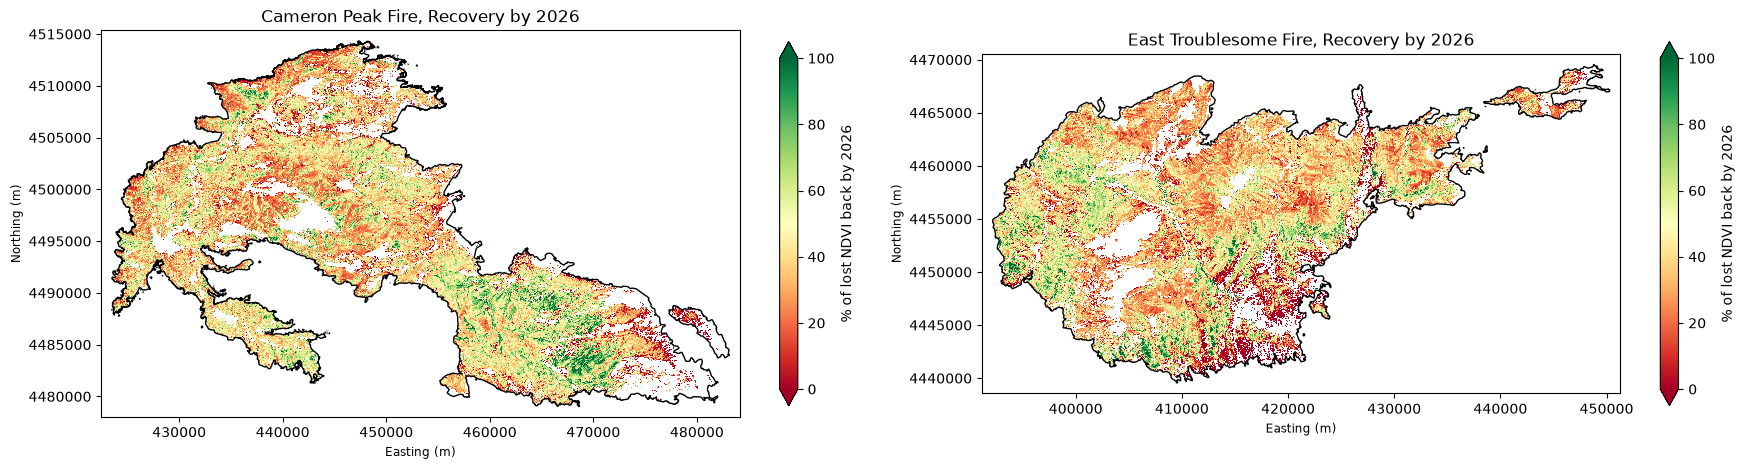

In [11]:
### the last summer, and the unburned land's NDVI in each year
last_year = recovery_years[-1]
reference_ndvi = reference_df.set_index(["fire", "year"])["reference_ndvi"]

### plot the recovery of each pixel by the last summer
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

for ax, fire in zip(axes, fire_keys):

    ### NDVI compared with the unburned land in the same summer
    before = ndvi_values[(fire, pre_fire_year)] - reference_ndvi[(fire, pre_fire_year)]
    after = ndvi_values[(fire, post_fire_year)] - reference_ndvi[(fire, post_fire_year)]
    latest = ndvi_values[(fire, last_year)] - reference_ndvi[(fire, last_year)]

    ### recovery where the relative NDVI dropped at least 0.1, inside the perimeter
    drop = before - after
    mapped = inside_masks[fire] & (drop >= min_ndvi_drop)
    recovery = np.full(drop.shape, np.nan)
    recovery[mapped] = (latest[mapped] - after[mapped]) / drop[mapped] * 100

    recovery_plot = ax.imshow(recovery, cmap="RdYlGn", vmin=0, vmax=100, extent=extents[fire], interpolation="nearest")
    fig.colorbar(recovery_plot, ax=ax, shrink=0.7, extend="both", label="% of lost NDVI back by " + str(last_year))

    ### add the fire perimeter, and zoom to it
    perimeter = perimeters_utm[perimeters_utm["fire"] == fire]
    perimeter.boundary.plot(ax=ax, color="black", linewidth=1)
    minx, miny, maxx, maxy = perimeter.total_bounds
    ax.set_xlim(minx - 1000, maxx + 1000)
    ax.set_ylim(miny - 1000, maxy + 1000)

    ax.ticklabel_format(style="plain")
    ax.set_title(fire.replace("_", " ").title() + " Fire, Recovery by " + str(last_year))
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

Figure 2: Percent of the NDVI lost from 2019 to 2021 that has come back by 2026, compared with the unburned land, with the NIFC perimeter in black. Red pixels have recovered the least, and green pixels are back to where they were in 2019. Blank pixels inside the perimeters lost less than 0.1 NDVI.

# 4. Save the Results
The mean NDVI and recovery for each fire, group, and year are saved to data/recovery.

In [12]:
### save the NDVI and recovery table
recovery_path = os.path.join(recovery_dir, "ndvi_recovery.csv")
ndvi_df.to_csv(recovery_path, index=False)

print("Saved NDVI and recovery table to:", recovery_path)

Saved NDVI and recovery table to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\recovery\ndvi_recovery.csv


# 5. Summary
By 2026, the Moderate-high and High areas have regained about 40-45% of the NDVI they lost in the fires, compared with the unburned land:
- Moderate-high and High: recovery went up almost every summer, to 45-46% at Cameron Peak and 39-43% at East Troublesome by 2026. Most of it came in the first three summers, and it has been slower since 2024
- High severity had the most to lose. These areas were the greenest before the fires (mean NDVI 0.68, compared with 0.55-0.61 for the other burned classes), likely dense forest. By 2026 they are about as green as the Moderate classes (Figure 1)
- Low and Moderate-low: these areas lost much less NDVI, so their recovery jumps around with the weather even after comparing with the unburned land. At East Troublesome, Low went from 56% in the wet summer of 2023 to 5% in 2026, the lowest unburned NDVI of any year. These areas seem to react more to wet and dry summers than the unburned forest, so their recovery percents aren't reliable from year to year

More than half of the greenness lost in the Moderate-high and High areas hasn't come back after five summers. NDVI measures greenness, so the forest itself is further from recovery than these numbers suggest.

# Citations
- Key, C. H., & Benson, N. C. (2006). Landscape assessment (LA): Sampling and analysis methods. In D. C. Lutes et al. (Eds.), *FIREMON: Fire effects monitoring and inventory system* (Gen. Tech. Rep. RMRS-GTR-164-CD, pp. LA-1-LA-55). USDA Forest Service, Rocky Mountain Research Station.
- Tucker, C. J. (1979). Red and photographic infrared linear combinations for monitoring vegetation. *Remote Sensing of Environment, 8*(2), 127-150. https://doi.org/10.1016/0034-4257(79)90013-0